# Knee osteoarthritis from X-rays, step by step (classical machine learning)

This notebook explains, one step at a time, how a computer can learn to tell a **healthy knee** from a knee with
**osteoarthritis (OA)** on an X-ray, **without deep learning**: only hand-crafted image features and scikit-learn models.

It is written for a reader who knows basic Python but has **no machine-learning background**. Every step has the same
structure:

- **What we do**: the action in one or two sentences.
- **Why**: the problem this step solves.
- **How it works**: the technique in plain words (intuition first, a small formula only when it helps).
- **The code**, short, and its **output**.
- **How to read this output**: what the numbers and plots of *this* run actually say.

Two kinds of results appear below and must not be confused:

1. **Live results**, computed in this notebook on a *subsample* of the training images so that it runs in a few minutes.
2. **Full-run results** (section 11), produced by `python -m kneeclf` on *all* training images and saved in
   `results/supervised/`. Those are the reference numbers of the project.

## 0. Setup

### Cell 1: every import of the notebook

All libraries are imported here, once, with what each one is used for. No other cell imports anything.
The project code lives in `src/kneeclf/`; we add `src/` to Python's search path so that `import kneeclf` works.

In [1]:
import sys                     # to add the project's src/ folder to the import path
import time                    # to time the slow steps (loading, training)
import json                    # to read the saved results of the full run (metrics.json)
from pathlib import Path       # file paths that work on every OS
from collections import Counter  # to count images per grade

import numpy as np             # arrays: an image is a 2-D array of numbers
import pandas as pd            # tables (DataFrame) to display counts and results
import matplotlib.pyplot as plt  # every figure of the notebook
from PIL import Image          # Pillow: opens the X-ray files (PNG) and the saved figures

from sklearn.preprocessing import StandardScaler            # puts every feature on the same scale
from sklearn.decomposition import PCA                       # compresses many features into a few
from sklearn.linear_model import LogisticRegression         # linear classifier
from sklearn.svm import SVC                                 # support vector machine classifier
from sklearn.pipeline import Pipeline                       # chains scaling -> PCA -> model
from sklearn.model_selection import StratifiedKFold         # splits data for cross-validation
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve  # evaluation

# Project modules (src/kneeclf). Works when the notebook runs from supervised_learning/ or from the repo root.
REPO = Path.cwd() if (Path.cwd() / "src" / "kneeclf").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO / "src"))
from kneeclf import data as kdata          # list / load / downscale / balance the images
from kneeclf import features as kfeat      # RawPixels and HOG feature extractors
from kneeclf import models as kmodels      # candidate pipelines and the GridSearchCV wrapper
from kneeclf import evaluate as keval      # scores, threshold choice, metrics

plt.rcParams.update({"figure.dpi": 80})          # small figures keep the notebook light
%config InlineBackend.figure_formats = ["jpeg"]  # JPEG figures: X-rays compress much better than in PNG
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.1.1


### Cell 2: parameters

| Name | Meaning |
|---|---|
| `DATA_ROOT` | Folder of the Kaggle *Knee Osteoarthritis Dataset with Severity Grading*: `train/`, `val/`, `test/`, each with sub-folders `0` to `4` (one per grade). The images are **not** in the repository (size and licence). |
| `RESULTS` | Saved outputs of the full training run (`python -m kneeclf --data <DATA_ROOT> --out runs`), copied to `results/supervised/`. |
| `SEED` | Seed of every random choice (sampling, cross-validation folds, PCA). Same seed = same numbers at every run. |
| `IMAGE_SIZE` | Side (in pixels) of the images after downscaling: 224 → 112. |
| `MAX_PER_CLASS_LIVE` | Number of training images kept per class for the live training of section 8 (the full run uses all of them). |
| `TARGET_RECALL` | Minimum share of OA knees the model must detect on validation when we choose the decision threshold (section 10). |

**If the images are not available**, sections 1 to 10 cannot run. Their outputs saved in this notebook stay readable,
and section 11 (full-run results) only needs the `results/supervised/` folder: run the cells of section 0 and 11.

In [2]:
DATA_ROOT = Path("/home/kkl/TEK2/S4/G-AIA-400-COT-4-1-cvrie-12/supervised_learning/Dataset_Knee_Osteoarthritis")
if not DATA_ROOT.is_dir():                                   # fallback: a copy next to the notebook
    DATA_ROOT = REPO / "supervised_learning" / "Dataset_Knee_Osteoarthritis"
RESULTS = REPO / "results" / "supervised"
SEED = 42
IMAGE_SIZE = 112
MAX_PER_CLASS_LIVE = 600
TARGET_RECALL = 0.85

HAVE_DATA = DATA_ROOT.is_dir()
print("images available:", HAVE_DATA, "| full-run results available:", (RESULTS / "metrics.json").exists())

images available: True | full-run results available: True


## 1. The dataset: knee X-rays graded 0 to 4

**What we do.** Count the images per grade and per split, and look at a few of them.

**Why.** Before any model, we must know what the data looks like: how many examples, how they are split, whether some
grades are rare. A model can only learn what the data shows.

**How it works.** Each image is a frontal X-ray of one knee, 224 × 224 pixels, in grey levels. A radiologist gave it a
**Kellgren–Lawrence (KL) grade**, the standard scale of knee osteoarthritis:

| KL grade | What the radiologist sees | Meaning |
|---|---|---|
| 0 | Nothing abnormal | healthy |
| 1 | *Doubtful* narrowing of the joint space, possible tiny osteophyte (bone spur) | doubtful |
| 2 | *Definite* osteophytes, possible narrowing | minimal OA |
| 3 | Several osteophytes, definite narrowing, some sclerosis (denser bone) | moderate OA |
| 4 | Large osteophytes, severe narrowing, bone deformation | severe OA |

The folders already split the data into three sets that never share an image:
**train** (to learn), **val** (validation: to choose settings and the decision threshold), **test** (to measure, once,
at the very end).

,train,val,test,share of train
KL grade,,,,
0,2286,328,639,0.396
1,1046,153,296,0.181
2,1516,212,447,0.262
3,757,106,223,0.131
4,173,27,51,0.030
total,5778,826,1656,1.000


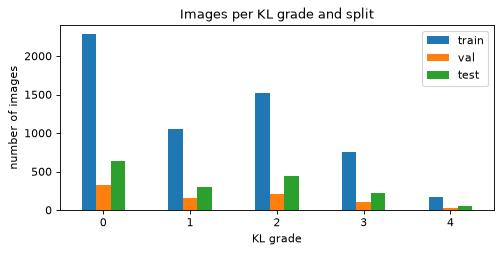

In [3]:
counts = {}
for split in ["train", "val", "test"]:
    items = kdata.list_split(DATA_ROOT, split)          # [(path, grade), ...]
    counts[split] = Counter(grade for _, grade in items)
counts_df = pd.DataFrame(counts).sort_index()
counts_df.index.name = "KL grade"
counts_df["share of train"] = (counts_df["train"] / counts_df["train"].sum()).round(3)
counts_df.loc["total"] = counts_df.sum().round(3)
display(counts_df)

ax = counts_df.drop(index="total")[["train", "val", "test"]].plot.bar(figsize=(7, 3), rot=0)
ax.set_ylabel("number of images"); ax.set_title("Images per KL grade and split")
plt.show()

#### How to read this output


- There are **5,778 training**, **826 validation** and **1,656 test** images: 8,260 X-rays in total.
- The grades are **far from equal**: KL 0 is 39.6 % of the training set, KL 4 only 3.0 % (173 images). Severe OA is rare,
  so a model will see few examples of it.
- The three splits have almost the same shape (the bars keep the same proportions), so validation and test look like
  the training data. That is what we want: scores measured on them will reflect what the model learned.

file: 9001695L.png | format: PNG | mode: L | size: (224, 224)


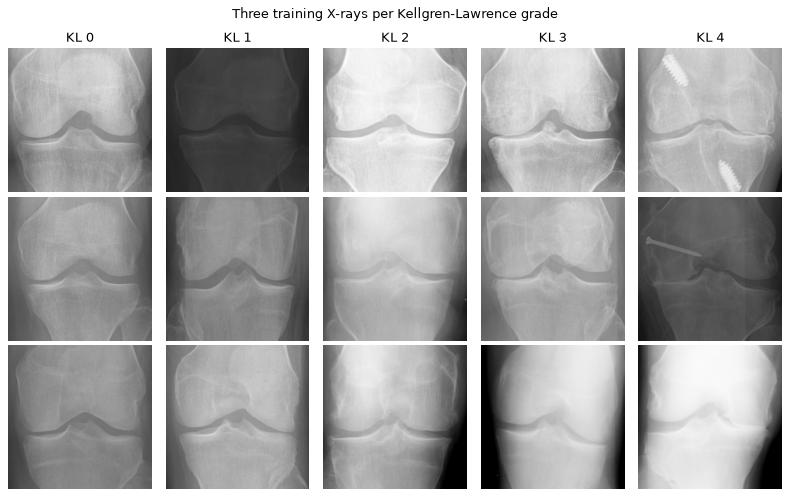

In [4]:
example_path = kdata.list_split(DATA_ROOT, "train")[0][0]
with Image.open(example_path) as im:
    print("file:", example_path.name, "| format:", im.format, "| mode:", im.mode, "| size:", im.size)

# Three random training images per grade
rng = np.random.default_rng(SEED)
train_items = kdata.list_split(DATA_ROOT, "train")
fig, axes = plt.subplots(3, 5, figsize=(10, 6.3))
for g in range(5):
    paths = [p for p, grade in train_items if grade == g]
    for row, p in enumerate(rng.choice(paths, size=3, replace=False)):
        axes[row, g].imshow(kdata.load_image(p), cmap="gray", vmin=0, vmax=1)
        axes[row, g].axis("off")
    axes[0, g].set_title(f"KL {g}")
fig.suptitle("Three training X-rays per Kellgren-Lawrence grade")
plt.tight_layout(); plt.show()

#### How to read this output


- Every file is a PNG of **224 × 224 pixels** in mode `L` (one grey channel, no colour).
- Across columns, the **gap between the two bones (the joint space)** becomes narrower and more irregular, and the bone
  edges get spikier: that is what the KL grade measures.
- Differences that have **nothing to do with OA** are just as visible: brightness and contrast change a lot between
  films (compare the dark KL 1 image with the very bright KL 4 one), and some KL 4 knees carry **metal screws or pins**
  from surgery. A model could learn to spot these shortcuts instead of the disease, which is a known risk of this dataset.

## 2. Labels: turning five grades into two classes

**What we do.** Map each KL grade to a binary label: **0 = no OA (KL 0–1)**, **1 = OA (KL 2–4)**.

**Why.** The project goal is a yes/no screening question: *does this knee show osteoarthritis?* Two choices were possible:

- **old scheme `KL0 vs KL1–4`**: anything above 0 is "sick". But KL 1 means *doubtful*: radiologists themselves disagree on
  it, so this scheme puts many ambiguous images in the "sick" class and teaches the model noise.
- **chosen scheme `KL0–1 vs KL2–4`**: the usual radiographic definition of OA in medical studies is **KL ≥ 2** (a *definite*
  osteophyte). The doubtful grade goes with "no OA".

**How it works.** A dictionary maps grade → label (`kdata.LABEL_SCHEMES`). We then count how many images fall in each
class, because an unbalanced dataset needs special care (next section).

In [5]:
schemes = pd.DataFrame(kdata.LABEL_SCHEMES).rename_axis("KL grade")
display(schemes)

train_grades = np.array([g for _, g in train_items])
balance = {}
for name, mapping in kdata.LABEL_SCHEMES.items():
    labels = np.array([mapping[g] for g in train_grades])
    balance[name] = {"negative (label 0)": int((labels == 0).sum()),
                     "positive (label 1)": int((labels == 1).sum()),
                     "share positive": round(float(labels.mean()), 3)}
display(pd.DataFrame(balance).T)

,kl0_vs_1to4,kl01_vs_2to4
KL grade,,
0,0,0
1,1,0
2,1,1
3,1,1
4,1,1


,negative (label 0),positive (label 1),share positive
kl0_vs_1to4,2286.0,3492.0,0.604
kl01_vs_2to4,3332.0,2446.0,0.423


#### How to read this output


- With the old scheme `kl0_vs_1to4`, 60.4 % of the training images are "positive": the doubtful KL 1 knees are counted as
  sick.
- With the chosen scheme `kl01_vs_2to4`, **2,446 knees (42.3 %) are OA** and **3,332 are not**. The classes are
  unbalanced (about 58 / 42), which section 3 corrects on the training set only.

## 3. Loading and preprocessing the images

**What we do.** (a) Turn each image into numbers between 0 and 1, (b) shrink it from 224 × 224 to 112 × 112,
(c) **balance the training set only**.

**Why.**
- (a) Computers only handle numbers. Dividing the grey levels (0 = black … 255 = white) by 255 gives values in [0, 1],
  the same for every image.
- (b) Fewer pixels = 4 times less memory and computing time. The joint space and the osteophytes stay visible at 112 px.
- (c) The training set has more "no OA" knees than "OA" knees. A model trained on it would lean towards "no OA" just because
  it is more frequent. We **randomly drop** "no OA" training images until both classes have the same count
  (*undersampling*). The **validation and test sets keep their real proportions**: they must look like the patients the
  model would really meet, otherwise the measured scores would be too optimistic.

**How it works.** The downscaling is an **area average**: each pixel of the small image is the mean of a 2 × 2 block of
the big one (`kdata.downscale`). This is smoother than keeping one pixel out of two, which would create jagged edges.

original : (224, 224) float32 min 0.137 max 0.898
downscaled: (112, 112) | top-left 2x2 block of the original:
 [[0.349 0.357]
 [0.349 0.357]] 
-> first pixel of the small image: 0.353


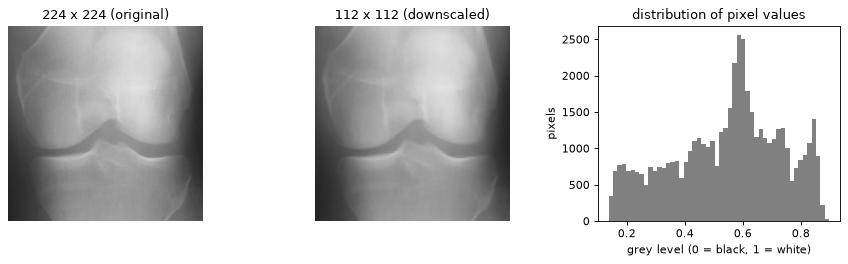

In [6]:
big = kdata.load_image(example_path)                 # 224 x 224, values in [0, 1]
small = kdata.downscale(big, IMAGE_SIZE)             # 112 x 112, mean of each 2 x 2 block
print("original :", big.shape, big.dtype, "min", big.min().round(3), "max", big.max().round(3))
print("downscaled:", small.shape, "| top-left 2x2 block of the original:\n", big[:2, :2].round(3),
      "\n-> first pixel of the small image:", small[0, 0].round(3))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].imshow(big, cmap="gray", vmin=0, vmax=1); axes[0].set_title("224 x 224 (original)")
axes[1].imshow(small, cmap="gray", vmin=0, vmax=1); axes[1].set_title(f"{IMAGE_SIZE} x {IMAGE_SIZE} (downscaled)")
axes[2].hist(big.ravel(), bins=50, color="grey"); axes[2].set_title("distribution of pixel values")
axes[2].set_xlabel("grey level (0 = black, 1 = white)"); axes[2].set_ylabel("pixels")
for a in axes[:2]: a.axis("off")
plt.tight_layout(); plt.show()

#### How to read this output


- After dividing by 255, the values of this image lie between **0.137 and 0.898**: no pixel is pure black or pure white.
- The four pixels of the top-left 2 × 2 block are 0.349, 0.357, 0.349, 0.357; their mean, **0.353**, is exactly the first
  pixel of the 112 × 112 image. That is the area average.
- The two images look the same to the eye: the bone edges and the joint space survive the downscaling.
- The histogram has most pixels in the middle greys (bone and soft tissue), with fewer dark pixels (the joint space and
  the background).

In [7]:
t0 = time.perf_counter()
train = kdata.load_split(DATA_ROOT, "train", image_size=IMAGE_SIZE, balance=True, seed=SEED)
val = kdata.load_split(DATA_ROOT, "val", image_size=IMAGE_SIZE, balance=False, seed=SEED)
print(f"loaded in {time.perf_counter() - t0:.1f} s")

rows = []
for s in (train, val):
    p = s.profile
    rows.append({"split": s.name, "files found": p["files_found"], "kept": p["kept"],
                 "label 0 kept": p["labels_kept"]["0"], "label 1 kept": p["labels_kept"]["1"],
                 "balanced": p["balanced"], "X shape": s.X.shape, "memory (MB)": p["memory_mb"]})
display(pd.DataFrame(rows))
display(pd.DataFrame({"train found": train.profile["grades_found"], "train kept": train.profile["grades_kept"]})
        .rename_axis("KL grade").T)

loaded in 9.1 s


,split,files found,kept,label 0 kept,label 1 kept,balanced,X shape,memory (MB)
0,train,5778,4892,2446,2446,True,"(4892, 12544)",234.1
1,val,826,826,481,345,False,"(826, 12544)",39.5


KL grade,0,1,2,3,4
train found,2286,1046,1516,757,173
train kept,1689,757,1516,757,173


#### How to read this output


- Loading and downscaling the 6,604 train + validation images took about 9 seconds.
- **Train**: 5,778 files found, **4,892 kept**, exactly **2,446 per class** after balancing. Only label-0 knees were dropped:
  KL 0 went from 2,286 to 1,689 and KL 1 from 1,046 to 757; every KL 2–4 image is kept.
- **Validation** keeps its 826 images and its real proportions (481 no OA / 345 OA), unbalanced on purpose.
- Each split is a table `X` with **one row per image and 12,544 columns** (112 × 112 pixels); the training table uses 234 MB.

In [8]:
# The live training of section 8 uses a random subsample of the balanced training set (MAX_PER_CLASS_LIVE per class).
keep = kdata.select_indices(train.y, max_per_class=MAX_PER_CLASS_LIVE, seed=SEED)
X_tr, y_tr = train.X[keep], train.y[keep]
X_val, y_val = val.X, val.y
print("live training set:", X_tr.shape, "| labels:", dict(Counter(y_tr.tolist())))
print("validation set   :", X_val.shape, "| labels:", dict(Counter(y_val.tolist())),
      f"| share OA = {y_val.mean():.3f}")

live training set: (1200, 12544) | labels: {0: 600, 1: 600}
validation set   : (826, 12544) | labels: {0: 481, 1: 345} | share OA = 0.418


#### How to read this output


- The live models of section 8 learn from **1,200 images (600 per class)**, a quarter of the balanced training set, so
  that the notebook runs in a couple of minutes. The full run (section 11) uses all 4,892.
- The validation set is complete: 826 images, **41.8 % OA**. This share matters later: it is the precision a model would
  get by answering "OA" at random.

## 4. Baseline: raw pixels as features

**What we do.** Give the model the pixels themselves: each 112 × 112 image becomes one row of 12,544 numbers.

**Why.** A **baseline** is the simplest reasonable approach. If a smarter method does not beat it, the smarter method is
useless. It also shows *why* we need better features.

**How it works.** **Flattening** reads the image row after row and puts all values one after the other: a 2-D image of
112 × 112 becomes a 1-D vector of 112 × 112 = 12,544 numbers. A classifier sees one number per pixel *position*.

The weakness: the model compares pixel #5,000 of one image with pixel #5,000 of another. If the knee is a few pixels
higher, or the X-ray is a bit brighter, **many of these numbers change**, although the knee is the same. Let us check that.

image (112, 112) -> vector (12544,) | first 5 values: [0.353 0.364 0.377 0.386 0.393]


,pixels changed by > 0.02,distance to original
shifted 4 px,0.350,5.630
brightness +0.10,1.000,11.200
another knee,0.858,12.162


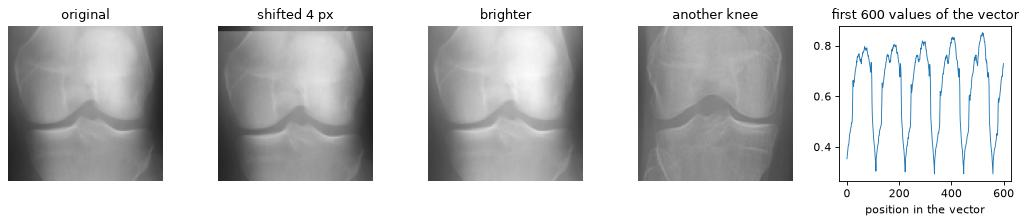

In [9]:
img = small
vec = img.ravel()                                         # flattening = reading the rows one after the other
print("image", img.shape, "-> vector", vec.shape, "| first 5 values:", vec[:5].round(3))

shifted = np.roll(img, 4, axis=0)                         # same knee, moved 4 pixels down
brighter = np.clip(img + 0.10, 0, 1)                      # same knee, brighter exposure
other = X_tr[1].reshape(IMAGE_SIZE, IMAGE_SIZE)            # a different patient

def dist(a, b):
    return np.linalg.norm(a.ravel() - b.ravel())          # Euclidean distance between two pixel vectors

table = pd.DataFrame({
    "pixels changed by > 0.02": [np.mean(np.abs(x - img) > 0.02) for x in (shifted, brighter, other)],
    "distance to original": [dist(x, img) for x in (shifted, brighter, other)],
}, index=["shifted 4 px", "brightness +0.10", "another knee"]).round(3)
display(table)

fig, axes = plt.subplots(1, 5, figsize=(13, 2.9))
for a, (im_, t) in zip(axes[:4], [(img, "original"), (shifted, "shifted 4 px"), (brighter, "brighter"), (other, "another knee")]):
    a.imshow(im_, cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
axes[4].plot(vec[:600], lw=0.8); axes[4].set_title("first 600 values of the vector")
axes[4].set_xlabel("position in the vector")
plt.tight_layout(); plt.show()

#### How to read this output


- The 112 × 112 image becomes a vector of **12,544 numbers**; the plot on the right shows the first 600 of them (the first
  five rows of pixels, one after the other), with a repeating pattern because each row crosses the same anatomy.
- **Brightness +0.10 changes 100 % of the pixels**, and its distance to the original (**11.2**) is almost as large as the
  distance to **a different patient's knee (12.2)**. For a model working on raw pixels, a brighter film of the same knee
  looks nearly as different as another person.
- A **4-pixel shift** changes 35 % of the pixels by more than 0.02 and gives a distance of 5.6, about half of the
  "other patient" distance.
- Conclusion: raw pixels mix up what we care about (the shape of the joint) with what we do not (exposure, position).

## 5. HOG: describing shapes instead of pixels

**What we do.** Replace the raw pixels by a **Histogram of Oriented Gradients (HOG)**, a classical description of the
*shapes* in an image (Dalal & Triggs, 2005).

**Why.** OA shows up as **shapes**: a narrower gap between the bones, sharp bone spurs, irregular edges. HOG describes
*where the edges are and which direction they point*, and it ignores overall brightness completely. It tolerates
shifts of a pixel or two (smaller than a cell), but not much more, as we will measure below.

**How it works**, in four ideas:

1. **Gradients.** At each pixel, how fast does the brightness change, and in which direction? Horizontal change
   `gx = right neighbour − left neighbour`, vertical change `gy = lower − upper`. The **magnitude** `√(gx² + gy²)` is large
   on edges (bone border, joint space) and near 0 in flat areas. The **orientation** `atan2(gy, gx)` is the edge direction,
   folded into 0–180° (a dark→bright and a bright→dark edge with the same direction count the same).
   Adding the same brightness to every pixel does **not** change any difference, so it does not change the gradients.
2. **Cells.** The image is cut into small squares of **8 × 8 pixels** (112 / 8 = 14 × 14 cells).
3. **Histograms with 9 bins.** In each cell, we build a histogram of the orientations: 9 bins of 20° (0–20°, 20–40°, …).
   Each pixel votes for its orientation **with a weight equal to its magnitude**, so strong edges count, noise barely does.
   The cell is now summarised by 9 numbers: "how much edge in each direction". Moving an edge by a pixel inside the
   cell does not change these numbers; moving it into the next cell does.
4. **Blocks and normalisation.** Groups of **2 × 2 cells** (a block, sliding by one cell → 13 × 13 blocks) are
   normalised together (divided by their length, values capped at 0.2, normalised again: "L2-Hys"). This removes local
   contrast differences, for example a darker area of the film.

Feature size = 13 × 13 blocks × (2 × 2 cells × 9 bins) = **6,084 numbers** per image, half the 12,544 raw pixels.

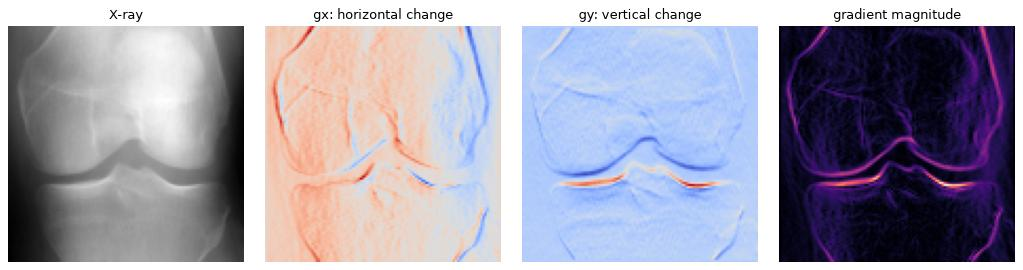

magnitude: median 0.021 | 99th percentile 0.129


In [10]:
# Step 1 by hand (same formulas as kfeat.HOG): gradients, magnitude, orientation
gx = np.zeros_like(img); gy = np.zeros_like(img)
gx[:, 1:-1] = img[:, 2:] - img[:, :-2]
gy[1:-1, :] = img[2:, :] - img[:-2, :]
magnitude = np.hypot(gx, gy)
orientation = np.rad2deg(np.arctan2(gy, gx)) % 180

fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for a, (m, t, cm) in zip(axes, [(img, "X-ray", "gray"), (gx, "gx: horizontal change", "coolwarm"),
                                (gy, "gy: vertical change", "coolwarm"), (magnitude, "gradient magnitude", "magma")]):
    a.imshow(m, cmap=cm); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()
print("magnitude: median", np.median(magnitude).round(3), "| 99th percentile", np.percentile(magnitude, 99).round(3))

#### How to read this output


- `gx` (red/blue) lights up on **vertical edges**, such as the outer borders of the bones; `gy` lights up on **horizontal
  edges**, such as the top and bottom borders of the joint space.
- The **magnitude** image is a drawing of the edges: bright on the bone contours and the joint line, dark inside the
  flat bone areas. Most pixels are flat: the median magnitude is **0.021**, while the strongest 1 % exceed **0.129**.
- This is the raw material of HOG: OA changes exactly these contours.

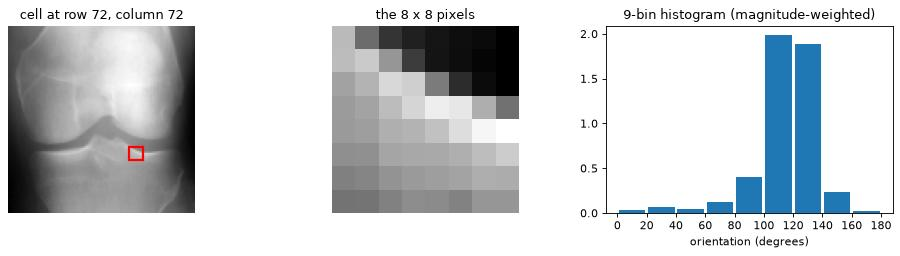

histogram: [0.03  0.07  0.046 0.124 0.398 1.991 1.889 0.239 0.021]


In [11]:
# Steps 2-3: one 8x8 cell and its 9-bin orientation histogram (each pixel votes with its magnitude)
r, c = np.unravel_index(np.argmax(magnitude[16:-16, 16:-16]), (IMAGE_SIZE - 32, IMAGE_SIZE - 32))
r, c = (r + 16) // 8 * 8, (c + 16) // 8 * 8                    # the cell containing the strongest edge
cell_mag, cell_ori = magnitude[r:r + 8, c:c + 8], orientation[r:r + 8, c:c + 8]
hist, edges = np.histogram(cell_ori, bins=9, range=(0, 180), weights=cell_mag)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].imshow(img, cmap="gray"); axes[0].add_patch(plt.Rectangle((c, r), 8, 8, fill=False, ec="red", lw=2))
axes[0].set_title(f"cell at row {r}, column {c}"); axes[0].axis("off")
axes[1].imshow(img[r:r + 8, c:c + 8], cmap="gray"); axes[1].set_title("the 8 x 8 pixels"); axes[1].axis("off")
axes[2].bar(edges[:-1] + 10, hist, width=18); axes[2].set_xticks(edges)
axes[2].set_xlabel("orientation (degrees)"); axes[2].set_title("9-bin histogram (magnitude-weighted)")
plt.tight_layout(); plt.show()
print("histogram:", hist.round(3))

#### How to read this output


- The cell chosen (row 72, column 72) contains the strongest edge of the central part of the image: it lies on the
  border of the joint space.
- Its 64 pixels vote into 9 bins. Almost all the weight falls in **100–120° (1.99) and 120–140° (1.89)**: the brightness
  changes mostly along one direction, i.e. the cell contains one clear, slanted edge. The other bins are close to 0.
- These 9 numbers replace 64 pixel values and say "a strong edge with this slope is here".

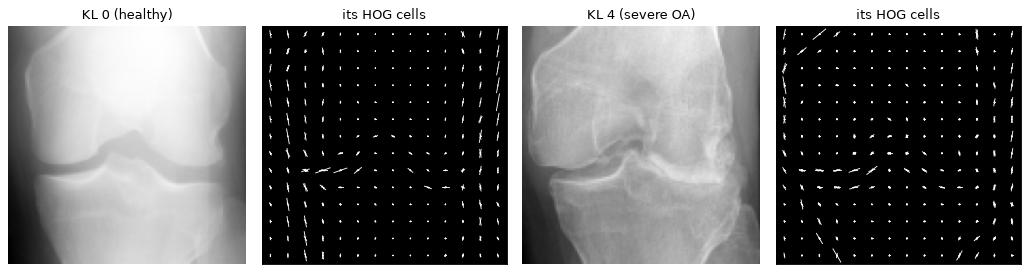

In [12]:
def cell_histograms(image, cell=8, bins=9):
    # Simplified HOG for display: per-cell orientation histograms, without block normalisation
    gx = np.zeros_like(image); gy = np.zeros_like(image)
    gx[:, 1:-1] = image[:, 2:] - image[:, :-2]; gy[1:-1, :] = image[2:, :] - image[:-2, :]
    mag, ori = np.hypot(gx, gy), np.rad2deg(np.arctan2(gy, gx)) % 180
    n = image.shape[0] // cell
    H = np.zeros((n, n, bins))
    for i in range(n):
        for j in range(n):
            sl = (slice(i * cell, (i + 1) * cell), slice(j * cell, (j + 1) * cell))
            H[i, j] = np.histogram(ori[sl], bins=bins, range=(0, 180), weights=mag[sl])[0]
    return H

def draw_hog(ax, H, cell=8):
    # One short line per bin, drawn ALONG the edge (perpendicular to the gradient), longer = stronger
    ax.set_facecolor("black"); top = H.max()
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            for b, w in enumerate(H[i, j]):
                theta = np.deg2rad(b * 20 + 10 + 90)
                dx, dy = np.cos(theta) * w / top * cell / 2, np.sin(theta) * w / top * cell / 2
                cx, cy = j * cell + cell / 2, i * cell + cell / 2
                ax.plot([cx - dx, cx + dx], [cy - dy, cy + dy], color="white", lw=0.8)
    ax.set_xlim(0, H.shape[1] * cell); ax.set_ylim(H.shape[0] * cell, 0); ax.set_xticks([]); ax.set_yticks([])

healthy = X_tr[np.flatnonzero(train.grades[keep] == 0)[0]].reshape(IMAGE_SIZE, IMAGE_SIZE)
severe = X_tr[np.flatnonzero(train.grades[keep] == 4)[0]].reshape(IMAGE_SIZE, IMAGE_SIZE)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for k, (im_, t) in enumerate([(healthy, "KL 0 (healthy)"), (severe, "KL 4 (severe OA)")]):
    axes[2 * k].imshow(im_, cmap="gray"); axes[2 * k].set_title(t); axes[2 * k].axis("off")
    draw_hog(axes[2 * k + 1], cell_histograms(im_)); axes[2 * k + 1].set_title("its HOG cells")
plt.tight_layout(); plt.show()

#### How to read this output


- Each small star is one 8 × 8 cell; each line is drawn **along** an edge direction, longer when the edge is stronger.
- On both knees, the strongest lines trace the **bone borders on the sides** (vertical lines) and the **joint line in
  the middle** (horizontal lines). The flat areas inside the bones are nearly empty.
- On the **KL 0** knee the joint line is a clean, regular band of horizontal strokes. On the **KL 4** knee the strokes
  around the joint are more irregular and point in more directions: the joint space is narrowed and the edges are
  rougher. The classifier will learn which of these patterns go with OA.

In [13]:
hog = kfeat.HOG(cell=8, block=2, bins=9)                 # the extractor used by the project
print("HOG output shape for one image (blocks, blocks, values per block):", hog.output_shape(IMAGE_SIZE))
f_img, f_shift, f_bright, f_other = hog.transform(np.stack([img, shifted, brighter, other]).reshape(4, -1))
print("feature vector length:", f_img.shape[0], "(raw pixels:", IMAGE_SIZE ** 2, ")")

rel = lambda a, b: np.linalg.norm(a - b) / np.linalg.norm(b)      # change relative to the original vector
display(pd.DataFrame({
    "raw pixels": [rel(shifted.ravel(), img.ravel()), rel(brighter.ravel(), img.ravel()), rel(other.ravel(), img.ravel())],
    "HOG": [rel(f_shift, f_img), rel(f_bright, f_img), rel(f_other, f_img)],
}, index=["shifted 4 px", "brightness +0.10", "another knee"]).round(3).rename_axis("relative change vs original"))

t0 = time.perf_counter()
H_tr, H_val = hog.transform(X_tr), hog.transform(X_val)
print(f"HOG of {len(X_tr) + len(X_val)} images in {time.perf_counter() - t0:.1f} s -> train {H_tr.shape}, val {H_val.shape}")

HOG output shape for one image (blocks, blocks, values per block): (13, 13, 36)
feature vector length: 6084 (raw pixels: 12544 )


,raw pixels,HOG
relative change vs original,,
shifted 4 px,0.087,0.453
brightness +0.10,0.174,0.000
another knee,0.189,0.649


HOG of 2026 images in 4.4 s -> train (1200, 6084), val (826, 6084)


#### How to read this output


- The project's extractor gives **13 × 13 blocks × 36 values = 6,084 numbers** per image, half of the 12,544 pixels.
- **Brightness +0.10 changes the HOG vector by 0.000**: gradients are differences, so adding a constant does nothing,
  while it changed the raw vector by 17 %, almost as much as another knee (19 %).
- The 4-pixel **shift**, however, changes HOG by 45 %, against 65 % for another knee. HOG is **not** shift-proof: 4 px is
  half a cell, so many edges move into a neighbouring cell. Its tolerance is only a pixel or two. The X-rays of this
  dataset are already centred on the joint, which limits the damage.
- Computing HOG for the 2,026 live images took about 4.5 seconds: HOG is cheap.

## 6. Scaling and PCA

**What we do.** (a) **Standardise** every feature; (b) for raw pixels, compress the 12,544 numbers into a few hundred
with a **Principal Component Analysis (PCA)**.

**Why.**
- (a) Many models (logistic regression, SVM) compare features with each other or use distances. A feature that varies
  between 0 and 100 would dominate one that varies between 0 and 0.01. Standardising gives each feature the same weight.
- (b) With 1,200 training images and 12,544 pixels, there are 10 times more numbers than examples: a model can then
  "memorise" the training images instead of learning (overfitting). Neighbouring pixels are also almost identical, so most
  of these numbers are redundant.

**How it works.**
- **Standardisation**: for each feature, subtract its mean and divide by its standard deviation, both measured *on the
  training set only*: `z = (x − mean) / std`. Afterwards each feature has mean 0 and standard deviation 1.
- **PCA** finds the directions along which the images vary the most. The first *principal component* is the "image
  pattern" that explains most of the differences between knees, the second explains most of what remains, and so on.
  Each image is then described by its coordinates on the first *k* components. The **explained variance** tells how much
  of the total variation the first *k* components keep.

,before: mean,before: std,after: mean,after: std
HOG feature 0,0.244,0.094,-0.0,1.0
HOG feature 1,0.054,0.069,0.0,1.0
HOG feature 2,0.021,0.039,0.0,1.0
HOG feature 3,0.013,0.023,-0.0,1.0
HOG feature 4,0.051,0.041,-0.0,1.0


first  10 components keep 94.3% of the pixel variance
first  50 components keep 97.6% of the pixel variance
first 100 components keep 98.4% of the pixel variance
first 200 components keep 99.1% of the pixel variance
first 300 components keep 99.4% of the pixel variance


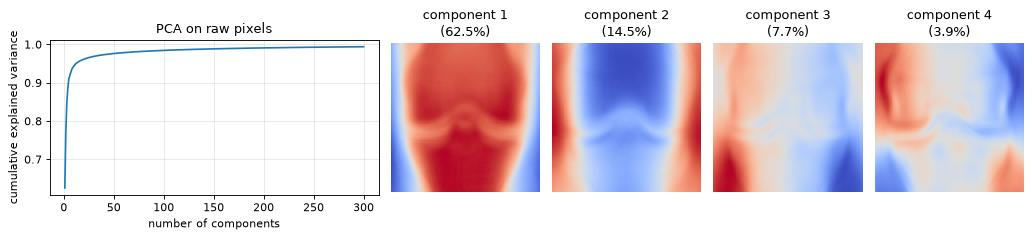

In [14]:
scaler = StandardScaler().fit(H_tr)                       # learns mean and std of each HOG feature on train only
H_tr_s = scaler.transform(H_tr)
display(pd.DataFrame({"before: mean": H_tr[:, :5].mean(0), "before: std": H_tr[:, :5].std(0),
                      "after: mean": H_tr_s[:, :5].mean(0), "after: std": H_tr_s[:, :5].std(0)},
                     index=[f"HOG feature {i}" for i in range(5)]).round(3))

raw_scaled = StandardScaler().fit_transform(X_tr)
pca = PCA(n_components=300, svd_solver="randomized", random_state=SEED).fit(raw_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)
for k in (10, 50, 100, 200, 300):
    print(f"first {k:3d} components keep {cum[k - 1]:.1%} of the pixel variance")

fig, axes = plt.subplots(1, 5, figsize=(13, 2.9), gridspec_kw={"width_ratios": [2.2, 1, 1, 1, 1]})
axes[0].plot(np.arange(1, 301), cum); axes[0].set_xlabel("number of components"); axes[0].set_ylabel("cumulative explained variance")
axes[0].set_title("PCA on raw pixels"); axes[0].grid(alpha=0.3)
for i, a in enumerate(axes[1:]):
    a.imshow(pca.components_[i].reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="coolwarm"); a.axis("off")
    a.set_title(f"component {i + 1}\n({pca.explained_variance_ratio_[i]:.1%})")
plt.tight_layout(); plt.show()

#### How to read this output


- **Standardisation**: the first five HOG features had means between 0.013 and 0.244 and very different spreads; after
  `StandardScaler`, every one has mean 0 and standard deviation 1.
- **PCA**: the raw pixels are extremely redundant. **10 components keep 94.3 %** of the pixel variance, 100 keep 98.4 %,
  200 keep 99.1 %. This is why the raw-pixel pipelines put a PCA with 50 to 200 components before the classifier.
- The component images are the main "directions of variation": **component 1 (62.5 %)** is essentially the overall
  brightness of the bones versus the background, **component 2 (14.5 %)** the width/position of the bones. These are
  exactly the nuisance factors seen in section 4: most of the variation between raw images is **not** about OA, which
  is why raw pixels give a weaker model.

## 7. The models, in plain words

A **classifier** receives a feature vector and outputs a **score**: the higher, the more "OA" the knee looks. A
**threshold** turns the score into a yes/no answer (section 10). The project compares four families:

| Model | Idea in plain words | Main settings (*hyperparameters*) |
|---|---|---|
| **Logistic regression** | Gives each feature a weight, adds them up (`score = w₁x₁ + w₂x₂ + … + b`) and squeezes the sum into a probability between 0 and 1. The boundary between the classes is a straight line (a flat "hyperplane" in many dimensions). Fast and easy to interpret. | `C`: how freely the weights may grow. Small `C` = strong **regularisation** (simple model, less overfitting); large `C` = fits the training data more closely. |
| **SVM with RBF kernel (`SVC`)** | Looks for the boundary that leaves the **widest margin** between the two classes. The *RBF kernel* measures similarity between two images as `exp(−gamma × distance²)`, which lets the boundary **curve** around groups of similar knees. | `C`: penalty for training images on the wrong side (large = fewer training errors, risk of overfitting). `gamma`: how far the influence of one image reaches (large = very local, wiggly boundary). `"scale"` sets it from the data variance. |
| **Random forest** | Builds hundreds of **decision trees** (series of yes/no questions such as "is feature 812 > 0.3?"), each on a random part of the data, and lets them vote. | number of trees, maximum depth, minimum samples per leaf. |
| **Histogram gradient boosting** | Also trees, but built **one after another**, each new tree correcting the errors of the previous ones. | learning rate, size of each tree. |

All of them use `class_weight="balanced"` (errors on both classes count the same). Random forest and gradient boosting
are slow on 6,084 features, so they are only trained in the full run (results in section 11).

To *see* the difference between a straight and a curved boundary, the cell below squeezes the HOG features into just
**2 numbers** with PCA (so that we can draw them) and trains a logistic regression and an SVM on those 2 numbers.
This toy version is far weaker than the real models, which use all the features.

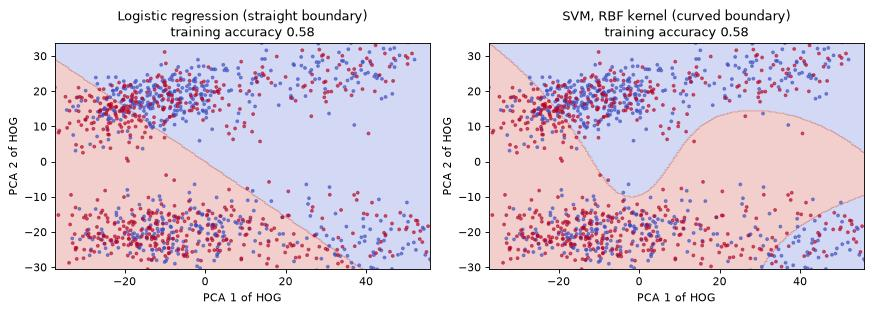

L knees: 100% have PCA 2 > 0
R knees: 0% have PCA 2 > 0


In [15]:
toy_pca = PCA(n_components=2, random_state=SEED).fit(H_tr_s)
P = toy_pca.transform(H_tr_s)
toy_models = {"Logistic regression (straight boundary)": LogisticRegression(class_weight="balanced"),
              "SVM, RBF kernel (curved boundary)": SVC(C=1, gamma="scale", class_weight="balanced")}
gx_, gy_ = np.meshgrid(np.linspace(*np.percentile(P[:, 0], [1, 99]), 200), np.linspace(*np.percentile(P[:, 1], [1, 99]), 200))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a, (name, m) in zip(axes, toy_models.items()):
    m.fit(P, y_tr)
    zone = m.predict(np.c_[gx_.ravel(), gy_.ravel()]).reshape(gx_.shape)
    a.contourf(gx_, gy_, zone, alpha=0.25, cmap="coolwarm")
    a.scatter(P[:, 0], P[:, 1], c=y_tr, cmap="coolwarm", s=6, alpha=0.6)
    a.set_title(f"{name}\ntraining accuracy {m.score(P, y_tr):.2f}"); a.set_xlabel("PCA 1 of HOG"); a.set_ylabel("PCA 2 of HOG")
    a.set_xlim(gx_.min(), gx_.max()); a.set_ylim(gy_.min(), gy_.max())
plt.tight_layout(); plt.show()

# What does PCA axis 2 capture? The last letter of each file name says which knee it is (L = left, R = right).
knee_side = np.array([Path(p).stem[-1] for p in np.array(train.paths)[keep]])
for side_ in ("L", "R"):
    print(f"{side_} knees: {np.mean(P[knee_side == side_, 1] > 0):.0%} have PCA 2 > 0")

#### How to read this output


- With only 2 numbers per knee, both models reach just **58 % training accuracy**: red (OA) and blue (no OA) points
  overlap almost everywhere. 2 numbers are far too few; the real models use all 6,084.
- The logistic regression can only draw **one straight line**; the SVM draws a **curved region** that follows the
  groups of points. The curve is more flexible, which helps when the classes are not separated by a straight line, but it
  can also bend around noise (overfitting); `C` and `gamma` control that.
- The points form **two big groups (top and bottom)**. The last two lines explain them: **100 % of left knees have
  PCA 2 > 0 and 0 % of right knees**. The second biggest difference between HOG vectors is simply *which knee* was
  X-rayed (a mirror image), not the disease. Linear and RBF models must learn to work across both.

## 8. Cross-validation and grid search: choosing settings honestly

**What we do.** For each model, try a few values of its settings (a **grid**) and keep the best, judged by
**3-fold cross-validation** on the training set. Then train it live on the subsample.

**Why.** We cannot judge settings on the training images themselves: a model that memorised them would look perfect.
We also must not use the test set (it is kept for the very end) and we keep the validation set for the threshold.
Cross-validation creates "mini test sets" *inside* the training data.

**How it works.**
- **K-fold cross-validation**: cut the training set into *K* = 3 parts (**folds**). Train on 2 parts, score on the third;
  repeat 3 times so that each part is scored once; average the 3 scores. *Stratified* means each fold keeps the same
  share of OA knees.
- **Grid search** (`GridSearchCV`): repeat the cross-validation for every combination of settings and keep the best one
  (here by **ROC AUC**, explained in section 9). The best combination is then retrained on the whole training subsample.
- The model is a **pipeline**: `StandardScaler → (PCA) → classifier`. Inside cross-validation, the scaler and the PCA are
  re-fitted on the 2 training folds only, so no information from the scored fold leaks into them.

round 1: train on 800 images, score on 400 (share OA 0.50)
round 2: train on 800 images, score on 400 (share OA 0.50)
round 3: train on 800 images, score on 400 (share OA 0.50)


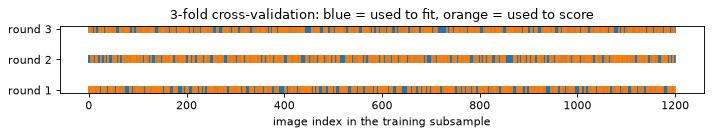

example pipeline: Pipeline(steps=[('scale', StandardScaler()),
                ('pca',
                 PCA(n_components=50, random_state=42,
                     svd_solver='randomized')),
                ('logreg',
                 LogisticRegression(class_weight='balanced', max_iter=3000))])


In [16]:
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
fig, ax = plt.subplots(figsize=(9, 1.8))
for k, (fit_idx, score_idx) in enumerate(folds.split(X_tr, y_tr)):
    ax.scatter(fit_idx, np.full(len(fit_idx), k), marker="|", s=40, color="tab:blue")
    ax.scatter(score_idx, np.full(len(score_idx), k), marker="|", s=40, color="tab:orange")
    print(f"round {k + 1}: train on {len(fit_idx)} images, score on {len(score_idx)} (share OA {y_tr[score_idx].mean():.2f})")
ax.set_yticks(range(3)); ax.set_yticklabels([f"round {k + 1}" for k in range(3)]); ax.set_xlabel("image index in the training subsample")
ax.set_title("3-fold cross-validation: blue = used to fit, orange = used to score"); plt.tight_layout(); plt.show()

print("example pipeline:", kmodels.build_pipeline("raw_pca_logreg", seed=SEED))

#### How to read this output


- Each of the 3 rounds fits on **800 images and scores on the other 400**; each round's scored part has exactly **50 %
  OA**, thanks to stratification.
- In the strip plot, every image is orange (scored) in exactly one round and blue (fitted) in the two others.
- The printed pipeline shows the three steps of `raw_pca_logreg`: `StandardScaler`, `PCA` (its `n_components` is one of
  the settings searched), then `LogisticRegression` with `class_weight="balanced"`.

In [17]:
live = {   # name: (training features, validation features, settings grid)
    "raw_pca_logreg": (X_tr, X_val, {"pca__n_components": [50, 200], "logreg__C": [0.001, 0.01]}),
    "hog_logreg":     (H_tr, H_val, {"logreg__C": [0.0003, 0.001, 0.01]}),
    "hog_svc":        (H_tr, H_val, {"svc__C": [1, 10], "svc__gamma": ["scale"]}),
}
searches, cv_rows = {}, []
for name, (Xf, _, grid) in live.items():
    gs, info = kmodels.search(name, Xf, y_tr, grid, cv_folds=3, refit="roc_auc", n_jobs=4, seed=SEED, verbose=0)
    searches[name] = gs
    res = pd.DataFrame(gs.cv_results_)
    for _, row in res.iterrows():
        cv_rows.append({"model": name, "settings": row["params"], "cv ROC AUC": round(row["mean_test_roc_auc"], 4),
                        "± (std)": round(row["std_test_roc_auc"], 4), "chosen": row["rank_test_roc_auc"] == 1})
    print(f"{name:15s} best {info['best_params']}  CV ROC AUC {info['cv']['roc_auc']:.4f}  ({info['search_seconds']:.1f} s)")
display(pd.DataFrame(cv_rows))

raw_pca_logreg  best {'logreg__C': 0.01, 'pca__n_components': 200}  CV ROC AUC 0.7490  (14.1 s)


hog_logreg      best {'logreg__C': 0.001}  CV ROC AUC 0.8218  (3.0 s)


hog_svc         best {'svc__C': 10, 'svc__gamma': 'scale'}  CV ROC AUC 0.8306  (32.2 s)


,model,settings,cv ROC AUC,± (std),chosen
0,raw_pca_logreg,"{'logreg__C': 0.001, 'pca__n_components': 50}",0.7280,0.0084,False
1,raw_pca_logreg,"{'logreg__C': 0.001, 'pca__n_components': 200}",0.7398,0.0094,False
2,raw_pca_logreg,"{'logreg__C': 0.01, 'pca__n_components': 50}",0.7334,0.0063,False
3,raw_pca_logreg,"{'logreg__C': 0.01, 'pca__n_components': 200}",0.7490,0.0099,True
4,hog_logreg,{'logreg__C': 0.0003},0.8201,0.0218,False
5,hog_logreg,{'logreg__C': 0.001},0.8218,0.0205,True
6,hog_logreg,{'logreg__C': 0.01},0.8075,0.0201,False
7,hog_svc,"{'svc__C': 1, 'svc__gamma': 'scale'}",0.8185,0.0215,False
8,hog_svc,"{'svc__C': 10, 'svc__gamma': 'scale'}",0.8306,0.0186,True


#### How to read this output


- Each line of the table is one combination of settings, scored by its average ROC AUC over the 3 folds (± its spread).
- **raw_pca_logreg**: best with 200 PCA components and `C = 0.01`, CV AUC **0.749**. More components helped
  (0.728 → 0.740 at `C = 0.001`).
- **hog_logreg**: best `C = 0.001`, CV AUC **0.822**. The larger `C = 0.01` is worse (0.808): with 6,084 features and
  800 training images per fold, a less regularised model starts to overfit.
- **hog_svc**: best `C = 10`, CV AUC **0.831**, the best of the three; it took ~32 s, against ~3 s for the HOG logistic
  regression.
- The ± values (0.006–0.022) show that differences of 0.01 between settings are close to the noise of the folds.
- **HOG features beat raw pixels by about 0.07–0.08 AUC** with the same model family: the features matter more than
  the classifier.

## 9. Measuring a classifier: the confusion matrix and its metrics

**What we do.** Score every validation knee with the 3 trained models and compare predictions with the truth.

**Why.** "Accuracy" alone hides what matters. In screening, **missing a sick knee** (it goes home untreated) is worse than
**a false alarm** (a doctor takes a second look). We need metrics that separate the two kinds of error.

**How it works.** With a threshold, each knee is predicted OA or not. Four cases (the **confusion matrix**):

|  | predicted no OA | predicted OA |
|---|---|---|
| **truly no OA** | TN (true negative) | FP (false positive, false alarm) |
| **truly OA** | FN (false negative, **missed** OA) | TP (true positive) |

- **Accuracy** = (TP + TN) / all: share of correct answers. Misleading when classes are unbalanced.
- **Recall** (= **sensitivity**) = TP / (TP + FN): of all OA knees, how many we caught. **The priority in medicine.**
- **Specificity** = TN / (TN + FP): of all healthy knees, how many we correctly cleared.
- **Precision** = TP / (TP + FP): when the model says "OA", how often it is right.
- **F1** = harmonic mean of precision and recall; **F2** = the same but recall counts twice as much as precision.
- **ROC curve**: recall (y) against false-alarm rate 1 − specificity (x) for *every* possible threshold.
  **AUC** (area under it) = probability that a random OA knee gets a higher score than a random healthy knee:
  0.5 = coin toss, 1.0 = perfect. It does not depend on the threshold, which is why it is used to choose the model.
- **PR curve**: precision against recall for every threshold; its area (*average precision*) focuses on the OA class.

hog_svc on validation, threshold 0:  TN=362  FP=119  FN=102  TP=243
accuracy    = (TP+TN)/all = 0.732
recall      = TP/(TP+FN)  = 0.704
specificity = TN/(TN+FP)  = 0.753
precision   = TP/(TP+FP)  = 0.671


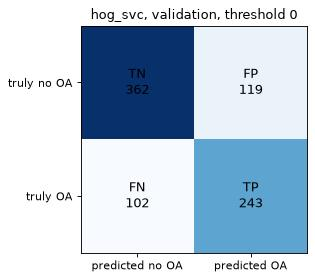

In [18]:
val_scores = {name: keval.decision_scores(searches[name].best_estimator_, live[name][1]) for name in live}
s = val_scores["hog_svc"]
pred = (s >= 0).astype(int)                       # SVC's natural threshold: decision score 0
tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
print(f"hog_svc on validation, threshold 0:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"accuracy    = (TP+TN)/all = {(tp + tn) / len(y_val):.3f}")
print(f"recall      = TP/(TP+FN)  = {tp / (tp + fn):.3f}")
print(f"specificity = TN/(TN+FP)  = {tn / (tn + fp):.3f}")
print(f"precision   = TP/(TP+FP)  = {tp / (tp + fp):.3f}")

fig, ax = plt.subplots(figsize=(4.2, 3.6))
cm = np.array([[tn, fp], [fn, tp]])
ax.imshow(cm, cmap="Blues")
for (i, j), lab in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ["TN", "FP", "FN", "TP"]):
    ax.text(j, i, f"{lab}\n{cm[i, j]}", ha="center", va="center", fontsize=12, color="black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["predicted no OA", "predicted OA"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["truly no OA", "truly OA"]); ax.set_title("hog_svc, validation, threshold 0")
plt.tight_layout(); plt.show()

#### How to read this output


- With the SVM's default threshold (score 0), out of 345 OA knees, **243 are caught (TP) and 102 are missed (FN)**; out of
  481 non-OA knees, 362 are cleared (TN) and 119 are false alarms (FP).
- Accuracy is **0.732**, but recall is only **0.704**: about **3 OA knees in 10 are missed**. Specificity (0.753) is
  higher than recall: the default threshold slightly favours "no OA".
- Precision 0.671: when the model says "OA", it is right two times out of three.
- For a screening tool, missing 30 % of patients is not acceptable, which is why section 10 moves the threshold.

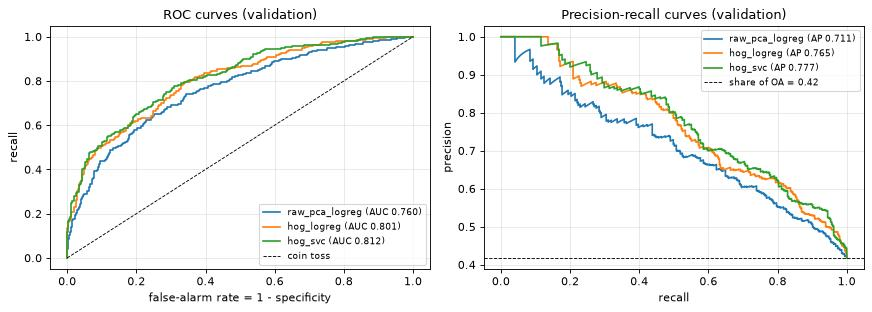

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, sc in val_scores.items():
    fpr, tpr, _ = roc_curve(y_val, sc)
    prec, rec, _ = precision_recall_curve(y_val, sc)
    m = keval.binary_metrics(y_val, sc, 0)   # AUCs do not depend on the threshold
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {m['roc_auc']:.3f})")
    axes[1].plot(rec, prec, label=f"{name} (AP {m['pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="coin toss")
axes[0].set_xlabel("false-alarm rate = 1 - specificity"); axes[0].set_ylabel("recall"); axes[0].set_title("ROC curves (validation)")
axes[1].axhline(y_val.mean(), color="k", ls="--", lw=0.8, label=f"share of OA = {y_val.mean():.2f}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision-recall curves (validation)")
for a in axes: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

#### How to read this output


- **ROC**: all three curves are well above the dashed "coin toss" diagonal. On validation, **hog_svc (AUC 0.812)** >
  **hog_logreg (0.801)** > **raw_pca_logreg (0.761)**: the same order as in cross-validation, so the choice is stable.
- An AUC of 0.81 means: take one OA knee and one non-OA knee at random, the model gives the OA knee the higher score
  81 % of the time.
- **Precision–recall**: the dashed line at **0.42** is the share of OA knees (what random guessing would give). Every
  model starts near precision 1 at low recall (the few knees with the highest scores are almost all OA), then precision
  falls as we try to catch more OA knees. Average precision: 0.777 (hog_svc), 0.765 (hog_logreg), 0.711 (raw).

## 10. The decision threshold

**What we do.** Choose the score above which a knee is called "OA", so that **at least 85 % of OA knees are detected**
on validation, and among those thresholds take the highest one (fewest false alarms).

**Why.** The model only outputs a score. The default cut (0 for an SVM, probability 0.5 for logistic regression) treats
both errors as equally bad. In screening they are not: we accept more false alarms to miss fewer patients.
Lowering the threshold raises recall and lowers specificity; the threshold is the **dial** between the two.

**How it works.** We try every possible threshold on the validation scores, compute recall and specificity for each, and
keep the highest threshold whose recall is still ≥ `TARGET_RECALL` (`keval.choose_threshold`). The threshold is chosen
on **validation**, never on test; the full run then applies it unchanged to the test set (section 11).

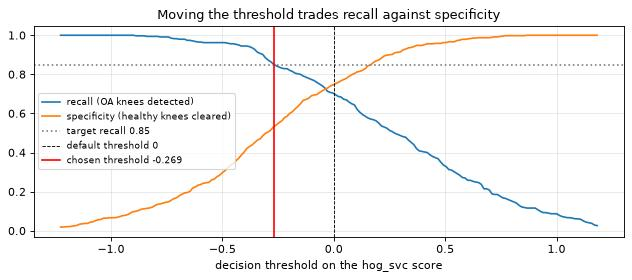

,threshold,accuracy,recall,specificity,precision,f1,f2,tn,fp,fn,tp
default (0),0.000,0.7324,0.7043,0.7526,0.6713,0.6874,0.6975,362.0,119.0,102.0,243.0
chosen,-0.269,0.6671,0.8522,0.5343,0.5676,0.6813,0.7745,257.0,224.0,51.0,294.0


In [20]:
thresholds = np.linspace(np.percentile(s, 1), np.percentile(s, 99), 200)
recall_curve = [np.mean(s[y_val == 1] >= t) for t in thresholds]
spec_curve = [np.mean(s[y_val == 0] < t) for t in thresholds]
chosen = keval.choose_threshold(y_val, s, mode="target_recall", target_recall=TARGET_RECALL)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(thresholds, recall_curve, label="recall (OA knees detected)")
ax.plot(thresholds, spec_curve, label="specificity (healthy knees cleared)")
ax.axhline(TARGET_RECALL, color="grey", ls=":", label=f"target recall {TARGET_RECALL}")
ax.axvline(0, color="k", lw=0.8, ls="--", label="default threshold 0")
ax.axvline(chosen, color="red", label=f"chosen threshold {chosen:.3f}")
ax.set_xlabel("decision threshold on the hog_svc score"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title("Moving the threshold trades recall against specificity"); plt.tight_layout(); plt.show()

rows = {}
for label, t in [("default (0)", 0.0), ("chosen", chosen)]:
    m = keval.binary_metrics(y_val, s, t)
    rows[label] = {k: m[k] for k in ["threshold", "accuracy", "recall", "specificity", "precision", "f1", "f2"]} | m["confusion_matrix"]
display(pd.DataFrame(rows).T)

#### How to read this output


- The blue curve (recall) falls and the orange one (specificity) rises when the threshold goes up: one cannot improve
  both at once.
- At the default threshold 0, recall is 0.704. The chosen threshold, **−0.269**, is the highest one that still reaches
  **recall ≥ 0.85**: recall becomes **0.852** (294 OA knees caught, only **51 missed** instead of 102).
- The price: specificity drops from 0.753 to **0.534** (224 false alarms instead of 119) and accuracy from 0.732 to
  0.667. Accuracy goes *down* while the tool becomes more useful for screening: accuracy is not the right target here.
- F2, which weighs recall twice, goes up from 0.698 to **0.775**.

In [21]:
live_rows = []
for name, sc in val_scores.items():
    t = keval.choose_threshold(y_val, sc, target_recall=TARGET_RECALL)
    m = keval.binary_metrics(y_val, sc, t)
    live_rows.append({"model": name, "val ROC AUC": m["roc_auc"], "val PR AUC": m["pr_auc"], "val recall": m["recall"],
                      "val specificity": m["specificity"], "val F2": m["f2"]})
live_df = pd.DataFrame(live_rows).set_index("model")
display(live_df)

,val ROC AUC,val PR AUC,val recall,val specificity,val F2
model,,,,,
raw_pca_logreg,0.7605,0.7110,0.8522,0.4428,0.7570
hog_logreg,0.8008,0.7649,0.8522,0.5655,0.7807
hog_svc,0.8121,0.7766,0.8522,0.5343,0.7745


#### How to read this output


- With each model's own threshold set for recall ≥ 0.85, they all reach the same recall **0.852**, so they can be compared on
  **specificity**: how many healthy knees they clear at that recall.
- **hog_logreg clears 56.6 %**, hog_svc 53.4 %, raw_pca_logreg only 44.3 %. At equal recall, HOG features again save
  many false alarms over raw pixels.
- hog_svc has the best AUC (0.812) but a slightly lower specificity than hog_logreg at this exact operating point: AUC
  summarises all thresholds, and at one particular threshold the ranking can switch. With 1,200 training images the
  two HOG models are within noise of each other.

## 11. Results of the full run (all training images)

**What we do.** Load the results saved by `python -m kneeclf` in `results/supervised/`, which trained **6 candidates on
the whole balanced training set (4,892 images)** with larger grids, picked the best by cross-validated ROC AUC, chose
the threshold on validation (recall ≥ 0.85), and evaluated **once on the test set**.

**Why the numbers differ from sections 8–10.** The live part used 1,200 training images (to run in minutes) and smaller
grids; more data usually gives a better model. Also, the live recall/specificity were measured on the same validation set
that chose the threshold, which is slightly optimistic; the full run's **test** numbers are the honest ones.

In [22]:
metrics = json.loads((RESULTS / "metrics.json").read_text())
comparison = pd.read_csv(RESULTS / "comparison.csv")
cols = ["candidate", "features", "cv_roc_auc", "val_roc_auc", "val_pr_auc", "val_recall", "val_specificity", "val_f2", "search_seconds"]
display(comparison[cols])
sel = metrics["selected"]
print("selected:", sel["candidate"], sel["best_params"], "| threshold", round(sel["threshold"], 4),
      "| total run time", round(metrics["timings"]["total_seconds"] / 60, 1), "min")

,candidate,features,cv_roc_auc,val_roc_auc,val_pr_auc,val_recall,val_specificity,val_f2,search_seconds
0,hog_svc,hog,0.8614,0.8607,0.8369,0.8522,0.6736,0.8028,622.89
1,hog_logreg,hog,0.8544,0.8566,0.8360,0.8522,0.6445,0.7967,19.47
2,hog_rf,hog,0.8217,0.8379,0.8024,0.8522,0.6341,0.7946,409.32
3,hog_pca_hgb,hog,0.8018,0.8093,0.7790,0.8522,0.5343,0.7745,759.41
4,raw_pca_svc,raw,0.7800,0.7924,0.7382,0.8522,0.5509,0.7778,70.06
5,raw_pca_logreg,raw,0.7856,0.7788,0.7460,0.8522,0.4823,0.7644,132.06


selected: hog_svc {'svc__C': 10, 'svc__gamma': 'scale'} | threshold -0.2003 | total run time 36.5 min


#### How to read this output


- The ranking of the full run matches the live run: **HOG models first, raw-pixel models last**.
- **hog_svc** wins on cross-validated AUC (**0.861**) and keeps it on validation (0.861), with the best specificity at
  recall 0.852 (**0.674**). hog_logreg is very close (val AUC 0.857) while its search took **19 s instead of 623 s**: if
  speed mattered more than the last 0.004 AUC, it would be the sensible choice.
- The tree models (random forest 0.838, gradient boosting 0.809) are below the linear and SVM models on these features
  and are slow.
- The selected threshold is **−0.200**, and the whole run (loading, 6 searches, evaluation) took **36.5 minutes**.

,validation (full run),test (full run)
n,826.0000,1656.0000
accuracy,0.7482,0.7566
balanced_accuracy,0.7629,0.7651
recall,0.8522,0.8308
specificity,0.6736,0.6995
precision,0.6519,0.6807
f1,0.7387,0.7483
f2,0.8028,0.7957
roc_auc,0.8607,0.8612
pr_auc,0.8369,0.8536


test confusion matrix: {'tn': 654, 'fp': 281, 'fn': 122, 'tp': 599}


,"live val ROC AUC (1,200 train images)","full-run val ROC AUC (4,892 train images)"
hog_logreg,0.8008,0.8566
hog_svc,0.8121,0.8607
raw_pca_logreg,0.7605,0.7788


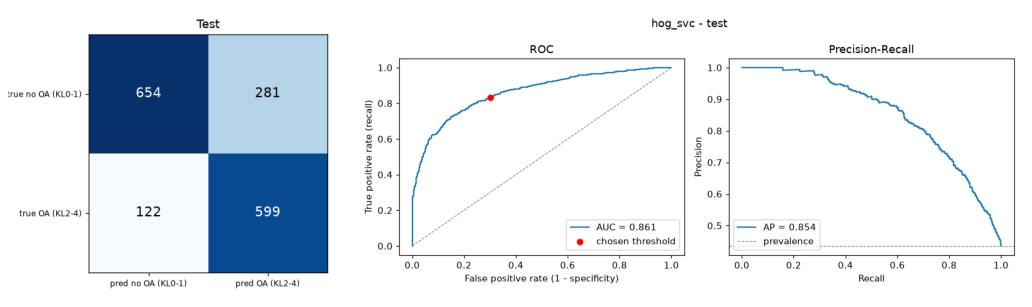

In [23]:
test, valm = metrics["test"], metrics["validation"]
keys = ["n", "accuracy", "balanced_accuracy", "recall", "specificity", "precision", "f1", "f2", "roc_auc", "pr_auc"]
display(pd.DataFrame({"validation (full run)": {k: valm[k] for k in keys}, "test (full run)": {k: test[k] for k in keys}}))
print("test confusion matrix:", test["confusion_matrix"])

compare = pd.DataFrame({"live val ROC AUC (1,200 train images)": live_df["val ROC AUC"],
                        "full-run val ROC AUC (4,892 train images)": comparison.set_index("candidate")["val_roc_auc"]}).dropna()
display(compare)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 2]})
for a, f in zip(axes, ["test_confusion.png", "test_curves.png"]):
    with Image.open(RESULTS / "figures" / f) as im:
        a.imshow(np.asarray(im)); a.axis("off")
plt.tight_layout(); plt.show()

#### How to read this output


- On the **1,656 test images**, never used before, the selected model reaches **recall 0.831** (599 of 721 OA knees found,
  122 missed), **specificity 0.700** (654 of 935 non-OA knees cleared, 281 false alarms), ROC AUC **0.861** and PR AUC
  **0.854**.
- Test recall (0.831) is a bit below the 0.85 aimed at on validation: a threshold tuned on one set never transfers
  exactly. It is close, and the test AUC equals the validation AUC (0.861), so the model did not overfit validation.
- **Live vs full run**: with 4 times more training images, validation AUC rises from 0.812 to **0.861** (hog_svc), 0.801 to
  0.857 (hog_logreg) and 0.761 to 0.779 (raw). More data helps the HOG models most. This is why the live numbers of
  sections 8–10 are lower than the reference numbers here.
- On the ROC curve, the red dot is the chosen operating point: we sit high on recall and pay with about 30 % false alarms.

## Summary of the steps

| # | Step | Technique | Key output of this run |
|---|---|---|---|
| 1 | Look at the data | counts, sample images | 8,260 X-rays; KL 4 only 3 % of train |
| 2 | Binary labels | KL 0–1 vs KL 2–4 | 42.3 % OA in train |
| 3 | Preprocessing | [0, 1] scaling, 224 → 112 area average, undersampling of train only | train balanced to 2 × 2,446; val keeps 41.8 % OA |
| 4 | Baseline features | flattened raw pixels | 12,544 numbers, fragile to shifts and brightness |
| 5 | Shape features | HOG (8 × 8 cells, 9 bins, 2 × 2 blocks, L2-Hys) | 6,084 numbers, brightness-invariant |
| 6 | Scaling & compression | StandardScaler, PCA | 10 PCA components keep 94 % of pixel variance |
| 7 | Models | logistic regression, SVM (RBF), random forest, gradient boosting | straight vs curved boundaries |
| 8 | Choosing settings | stratified 3-fold CV + GridSearchCV on ROC AUC | live CV AUC: raw 0.749, HOG-LogReg 0.822, HOG-SVC 0.831 |
| 9 | Metrics | confusion matrix, recall, specificity, ROC/PR AUC | live hog_svc at threshold 0: recall 0.704, val AUC 0.812 |
| 10 | Threshold | highest threshold with validation recall ≥ 0.85 | 8,260 X-rays; KL 4 only 3 % of train0 |
| 11 | Full run | 6 candidates, all training data, test once | 8,260 X-rays; KL 4 only 3 % of train1 |

## Conclusion and limitations

**What works.** Describing the X-ray by the *shape of its edges* (HOG) instead of its pixels is the decisive step:
with the same classifier, it adds about 0.07–0.08 ROC AUC, it ignores exposure, and it is cheap to compute. The selected
model, an RBF SVM on HOG features, detects **83 % of OA knees on unseen test images with 70 % specificity**
(AUC 0.861). Choosing the threshold for recall instead of accuracy is what makes it usable as a screening aid: the
default threshold would miss about 3 OA knees in 10.

**Limitations.**
- **Classical features have a ceiling.** HOG sees edges in fixed 8 × 8 cells; it does not know anatomy and tolerates only
  shifts of a pixel or two. Convolutional networks trained on this kind of data usually do better; they were outside
  this project's allowed libraries.
- **Not a diagnostic tool.** About 30 % false alarms and 17 % missed OA knees on test; trained on a single public dataset
  whose grading reliability is not documented; no external validation on other hospitals or devices. It must not be used on patients.
- **Labels are noisy at the border.** KL 1 vs KL 2 is the hardest and most debated distinction; part of the error is in
  the labels themselves.
- **Shortcuts are possible.** Brightness differences, left/right orientation and surgical hardware (screws on some
  KL 4 knees) differ between images independently of OA; we did not prove that the model ignores them.
- **Rare severe cases.** KL 4 is only 3 % of the data; the binary label hides how errors spread across grades.
- **Live vs reference numbers.** Sections 8–10 use 1,200 training images and score on the validation set that chose the
  threshold; the reference figures are the full-run test results of section 11.